# Verne, small, step 03: VAE latents (roadmap box 02), on T1-wide

What's new and how shapes flow: `03_vae_latents_explained.ipynb`. Step 02: `02_cosine_lr.ipynb`.

One box opened: the input goes through a VAE. Verne encodes every frame with the frozen Wan2.2 VAE encoder and patches the latent grid (`../verne-v0.5/src/verne/model/vae.py`). Here a small VAE of the same shape (`vae.py`: residual convs with RMS norm + SiLU, stride-2 halvings, mean and log-variance, the mean normalised per channel), trained on our own frames, frozen. The [top | wrist] canvas 3 × 128 × 256 → latent 4 × 16 × 32; the video transformer reads 2 × 2 latent squares (16 numbers each) → 8 × 16 = 128 tokens, the same 128 as the 16 × 16 pixel patches. Everything else as step 02 (cosine LR).

```-
[top | wrist] ─► VAE encoder (frozen) ─► latent 4 x 16 x 32 ─► 2x2 squares ─► VIDEO transformer ── k,v ─┐
joints ─────────────────────────────────────────────────────► one more token ┘                          │
noise [16 x 8] ─► ACTION transformer ◄───────────────────────────────────────────────────────────────────┘
                  10 flow steps ─► 16 joint actions
```

Runs are jobs (`python -m dream_robot.policies.verne.run ...`, files under `experiments/verne/runs/03_vae_latents/`); this notebook only reads them. All on the RunPod L40S, like step 02's T1-wide seeds.

In [ ]:
import json

import numpy as np
from IPython.display import Image

from dream_robot.policies.verne import vae
from dream_robot.policies.verne.run import RUNS

VAE_RUN = RUNS / '03_vae_latents' / 'vae'

### step 03.1 — the VAE

Trained once (`run vae 03_vae_latents`) on the canvases of both tasks' training demos (39,327 frames; val episodes held out, every 40th val frame scored), 5k steps, batch 64, lr 1e-3, β = 1e-3 on the KL. Losses: MSE in [-1, 1] pixel units, KL per latent number.

In [ ]:
for step, rec, kl, v_rec, v_kl in json.loads((VAE_RUN / 'log.json').read_text())[::2]:
    print(f'step {step:5.0f}   train {rec:.4f} KL {kl:.3f}   val {v_rec:.4f} KL {v_kl:.3f}')

step     0   train 0.7996 KL 0.035   val 0.3737 KL 0.223
step  1000   train 0.0046 KL 1.282   val 0.0047 KL 1.284
step  2000   train 0.0026 KL 1.054   val 0.0027 KL 1.049
step  3000   train 0.0021 KL 0.908   val 0.0022 KL 0.908
step  4000   train 0.0025 KL 0.812   val 0.0024 KL 0.799
step  5000   train 0.0016 KL 0.741   val 0.0015 KL 0.737


Six val canvases, real (top row) and decoded from the mean latent (bottom row):

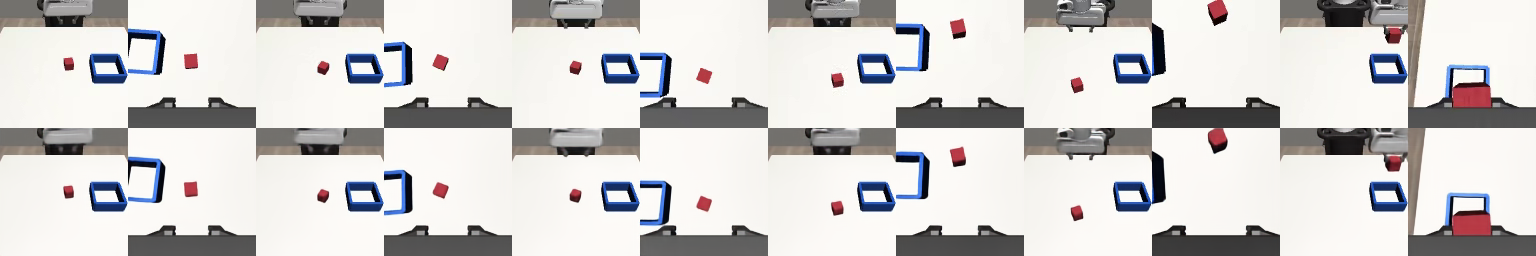

In [ ]:
Image(VAE_RUN / 'recon.png')

### step 03.2 — the latents

Every canvas of each dataset encoded once (mean, normalised by the VAE's per-channel stats) into `data/robosuite/<name>/decoded/latents_<weights hash>.npy`, float16. Per channel: mean and std over all frames, should be ≈ 0 and ≈ 1.

In [ ]:
for name in ('pick_place_cube_n100', 'pick_place_cube_wide_n100'):
    z = vae.load_latents(name, vae.WEIGHTS).astype(np.float32)  # [N, 4, 16, 32]
    print(
        f'{name:26s} {z.shape}  mean {z.mean((0, 2, 3)).round(3)}  std {z.std((0, 2, 3)).round(3)}'
    )

pick_place_cube_n100       (21295, 4, 16, 32)  mean [ 0.003  0.001 -0.001  0.001]  std [0.999 0.996 1.    1.001]
pick_place_cube_wide_n100  (22409, 4, 16, 32)  mean [-0.002 -0.001  0.001 -0.   ]  std [0.998 1.001 0.999 1.   ]


### step 03.3 — T1-wide, 3 training seeds × 50 rollout seeds, against step 02

Each seed: `run job 03_vae_latents t1-wide <seed>` (20k steps, sweeps at n_exec 8 and 16, close-point probe at n_exec 8). Step 02 (cosine LR, pixels): `experiments/verne/runs/02_cosine_lr/`, same GPU.

In [ ]:
def read_run(step: str, task: str, seed: int):
    # one run folder -> meta, log [(step, train, val)], n_exec -> successes, probe fit (T1-wide)
    d = RUNS / step / task / f'seed{seed}'
    sweeps = {n: json.loads((d / f'sweep_{n}.json').read_text()) for n in (8, 16)}
    probe = d / 'probe.json'
    return {
        'meta': json.loads((d / 'meta.json').read_text()),
        'log': json.loads((d / 'log.json').read_text()),
        'ok': {n: sum(r[0] for r in s.values()) for n, s in sweeps.items()},
        'fit': json.loads(probe.read_text())['fit'] if probe.exists() else None,
    }

In [ ]:
for step in ('02_cosine_lr', '03_vae_latents'):
    runs = [read_run(step, 't1-wide', seed) for seed in (0, 1, 2)]
    for seed, r in enumerate(runs):
        f = r['fit']
        print(
            f'{step:15s} seed {seed}: n_exec 8 {r["ok"][8]:2d}/50, 16 {r["ok"][16]:2d}/50, '
            f'val end {r["log"][-1][2]:.3f}, probe x {f["slope_x"]:+.2f} y {f["slope_y"]:+.2f} '
            f'miss {f["miss_cm"]:.1f} cm'
        )
    print(
        f'{step:15s} total : n_exec 8 {sum(r["ok"][8] for r in runs)}/150, '
        f'16 {sum(r["ok"][16] for r in runs)}/150\n'
    )

02_cosine_lr    seed 0: n_exec 8  9/50, 16  4/50, val end 0.043, probe x +0.73 y +0.55 miss 3.3 cm
02_cosine_lr    seed 1: n_exec 8 11/50, 16  6/50, val end 0.031, probe x +0.05 y +0.01 miss 8.7 cm
02_cosine_lr    seed 2: n_exec 8  9/50, 16  4/50, val end 0.036, probe x +0.23 y +0.06 miss 7.6 cm
02_cosine_lr    total : n_exec 8 29/150, 16 14/150

03_vae_latents  seed 0: n_exec 8 34/50, 16 36/50, val end 0.035, probe x +0.99 y +0.96 miss 1.4 cm
03_vae_latents  seed 1: n_exec 8 36/50, 16 37/50, val end 0.031, probe x +0.95 y +0.80 miss 1.4 cm
03_vae_latents  seed 2: n_exec 8 42/50, 16 39/50, val end 0.028, probe x +0.99 y +0.95 miss 1.1 cm
03_vae_latents  total : n_exec 8 112/150, 16 112/150



### wrap-up — VAE latents (box 02): done on T1-wide, 3 seeds; T1 not run

```-
T1-wide, 3 seeds × 50   n_exec 8   n_exec 16   finds the cube   close-point miss
step 02, pixels          29/150     14/150       1 of 3          3.3  8.7  7.6 cm
step 03, VAE latents    112/150    112/150       3 of 3          1.4  1.4  1.1 cm
```

**What it buys:** the policy finds the cube, every seed (x slope +0.95 to +0.99, y +0.80 to +0.96: the gripper closes where the cube is), and success goes ~4× (29 → 112 at n_exec 8, 14 → 112 at 16). Seeds agree: 34 / 36 / 42 and 36 / 37 / 39, the spread step 02 set out to cut. Training is cheaper too: latents are 90 MB per dataset against 2.2 GB of frames, ~6 min per job with sweeps on the L40S.

**Where it fails:** 8-16 episodes per seed still end `no_grasp` (a few `dropped`): the reach is right, the grasp misses. Not yet looked at why. T1 (10 demos) not run, so whether latents help there, where step 02 overfit, is open.

**Why it might work** (not tested): a pixel patch is 768 raw numbers dominated by the white table; a latent square is 16 numbers the VAE trained to keep what's needed to redraw the scene, and the red cube is the part of the picture a pixel loss can't afford to lose. The video transformer gets the cube's position pre-digested instead of finding it in raw pixels.

**Not Verne's yet:** our VAE is trained on these frames (Verne's is Wan2.2's, frozen, pretrained on web video), 8× down with 4 channels (Wan: 16×, 48 channels), no attention or average-pool shortcuts. Matching it is later work.